## CSCI-5622 - Final Project
### Jenn Kaphammer, 11/15/2026
Reproduction: Begin at Section 2 to evaluate the supplied 4,000-recording feature CSV. Section 1 is optional and requires downloading the original WAV files. The visualizations below use the same held-out fold predictions/results as the statistical analysis.

#### 0. The Modeling Decision
The decision-maker is a municipal noise-monitoring official who must decide which audio recordings should be flagged for human review. The classifier predicts whether a recording contains drilling or jackhammer sounds (positive class, 1) rather than children playing or street music (negative class, 0).

A false positive occurs when a non-target recording is flagged for review, creating unnecessary workload for municipal staff. A false negative occurs when a drilling or jackhammer recording is not flagged, potentially missing a relevant event.

For this decision, I prioritize avoiding unnecessary reviews while still detecting disruptive sounds. Therefore, false positives are considered more costly, motivating the use of $F_{0.5}$, which emphasizes precision over recall.

The model is intended to support human review: not automatically determine whether a noise ordinance has been violated.

The project retains the three locked decisions from the original proposal: the all-positive baseline, the ten predefined UrbanSound8K folds for held-out evaluation, and mean $F_{0.5}$ as the primary evaluation metric.

In addition to the declared all-positive baseline, a loudness-only threshold classifier was added to determine whether the trained models learned information beyond recording intensity. This additional baseline does not replace the original baseline.

Hyperparameters and classification thresholds were selected using inner cross-validation within the nine training folds, preserving the original held-out evaluation structure.

In [107]:
#import packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import librosa
import librosa.feature
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    fbeta_score,
    precision_score,
    recall_score,
    confusion_matrix
)

### **1. Loading & feature Extraction of the UrbanSound8K dataset**
#### **Running is optional: this will regenerate acoustic features from raw audio (~6GB)**
Running this is not required to reproduce the model evaluate results. The computed features have been extracted in data/urban_features.csv. If you do not want to regenerate acoustic features with these functions and instead use the pre-computed dataset, move on to section 2.

In [9]:
import kagglehub
from pathlib import Path

path = Path(kagglehub.dataset_download("chrisfilo/urbansound8k"))

print("Dataset location:", path)

Resuming download from 3563061248 bytes (2463171276 bytes left)...
Resuming download to /Users/nicejeans/.cache/kagglehub/datasets/chrisfilo/urbansound8k/1.archive (3563061248/6026232524) bytes left.


100%|██████████| 5.61G/5.61G [03:46<00:00, 10.9MB/s]

Extracting files...


Dataset location: /Users/nicejeans/.cache/kagglehub/datasets/chrisfilo/urbansound8k/versions/1


In [22]:
#find audio recordings
audio_files = list(path.rglob("*.wav"))
print("Number of audio files:", len(audio_files))

Number of audio files: 8732


In [10]:
metadata_file = next(path.rglob("UrbanSound8K.csv"))
df = pd.read_csv(metadata_file)
df.head()

,slice_file_name,fsID,start,end,salience,fold,classID,class
0,100032-3-0-0.wav,100032,0.0,0.317551,1,5,3,dog_bark
1,100263-2-0-117.wav,100263,58.5,62.500000,1,5,2,children_playing
2,100263-2-0-121.wav,100263,60.5,64.500000,1,5,2,children_playing
3,100263-2-0-126.wav,100263,63.0,67.000000,1,5,2,children_playing
4,100263-2-0-137.wav,100263,68.5,72.500000,1,5,2,children_playing


In [13]:
classes = [
    "drilling",
    "jackhammer",
    "children_playing",
    "street_music"
]

df = df[df["class"].isin(classes)].copy()

df["target"] = df["class"].isin(
    ["drilling", "jackhammer"]
).astype(int)

print(df["class"].value_counts())
df.tail()

class
children_playing    1000
street_music        1000
jackhammer          1000
drilling            1000
Name: count, dtype: int64


,slice_file_name,fsID,start,end,salience,fold,classID,class,target
8718,99710-9-0-12.wav,99710,6.0,10.0,1,6,9,street_music,0
8719,99710-9-0-16.wav,99710,8.0,12.0,1,6,9,street_music,0
8720,99710-9-0-2.wav,99710,1.0,5.0,1,6,9,street_music,0
8721,99710-9-0-5.wav,99710,2.5,6.5,1,6,9,street_music,0
8722,99710-9-0-6.wav,99710,3.0,7.0,1,6,9,street_music,0


#### Extract audiowave features from wav files
A **Mel-frequency cepstral coefficients (MFCC)** produces a sequence of measurements for each coefficient throughout a recording. We can calculate the mean and standard deviation to get frequency characteristics of the sound waves over time.
$$ \text{MFCC}_j\text{ mean}=\frac{1}{T}\sum_{t=1}^{T}MFCC_j(t)$$ and $$\text{MFCC}_j\text{ standard deviation}=
\sqrt{\frac{1}{T}\sum_{t=1}^{T}(MFCC_j(t)-\overline{MFCC}_j)^2}$$
We can choose a fixed number of MFC coefficients to give each audio clip has same number of features, regardless of audioclip length. To start, **20 coefficients will be used.**
(Note: means and standard deviations summarize sound over time but lose the exact ordering of events.)

Other metrics we will calculate include the root mean square (RMS) energy, spectral centroid, spectral rolloff, zero-crossing rate, and spectral flatness (see pdf report in repo for full description of these.)

In [37]:
def extract_audio_features(audio_path):
    #sample rate in urban8k dataset is commonly at 44100 HZ
    y, sr = librosa.load(audio_path, sr=44100, mono=True)
    features = {}

    #store mean and SD
    def sum_mean_sd(name, vals):
        features[name + "_mean"] = np.mean(vals)
        features[name + "_std"] = np.std(vals)

    #MFCC with 20 coeff x2 = 40 features
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    for i in range(20):
        sum_mean_sd(f"mfcc_{i+1}", mfcc[i])

    #RMS energy
    rms = librosa.feature.rms(y=y)
    sum_mean_sd("rms", rms)

    #spectral centroid
    spectral_centroid_ = librosa.feature.spectral_centroid(y=y, sr=sr)
    sum_mean_sd("spectral_centroid", spectral_centroid_)

    #spectral rolloff
    spectral_rolloff_ = librosa.feature.spectral_rolloff(y=y, sr=sr)
    sum_mean_sd("spectral_rolloff", spectral_rolloff_)

    #zero-crossing rate
    zero_cr = librosa.feature.zero_crossing_rate(y=y)
    sum_mean_sd("zero_cr", zero_cr)

    #spectral flatness
    flatness = librosa.feature.spectral_flatness(y=y)
    sum_mean_sd("spectral_flatness", flatness)

    #metadata
    features["duration"] = len(y)/sr
    return features

In [38]:
#test on one audio file
print("Audio files found:", len(audio_files))

if not audio_files:
    raise FileNotFoundError(
        "No WAV files found. Check the Kaggle dataset directory."
    )

test_audio = audio_files[0]

test_features = extract_audio_features(test_audio)

print("Recording:", test_audio.name)
print("Number of values:", len(test_features))

pd.DataFrame([test_features])

Audio files found: 8732
Recording: 203929-7-5-1.wav
Number of values: 51


,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,mfcc_5_mean,mfcc_5_std,...,rms_std,spectral_centroid_mean,spectral_centroid_std,spectral_rolloff_mean,spectral_rolloff_std,zero_cr_mean,zero_cr_std,spectral_flatness_mean,spectral_flatness_std,duration
0,-236.12149,7.005122,237.696655,5.179524,-48.400726,5.353018,35.357746,4.781607,-14.744243,4.385653,...,0.009577,1353.085327,95.319031,2602.708984,278.275452,0.036134,0.005015,0.000162,0.000047,4.0


##### Extract features from all 4 classes

In [39]:
#match audio to metadata w/ lookup dictionary
audio_lookup = {
    (int(p.parent.name.replace("fold", "")), p.name): p
    for p in audio_files
    if p.parent.name.startswith("fold")
    and p.parent.name.replace("fold", "").isdigit()
}
print("Audio files indexed:", len(audio_lookup))

Audio files indexed: 8732


In [40]:
#recheck to make sure correct classes are in def
print(df["class"].value_counts())
print("Total recordings to process:", len(df))

class
children_playing    1000
street_music        1000
jackhammer          1000
drilling            1000
Name: count, dtype: int64
Total recordings to process: 4000


In [41]:
from tqdm.auto import tqdm #used for progress bar since large dataset

# Features from WAV files
records = []

for _, row in tqdm(df.iterrows(), total=len(df), desc="Extracting audio features"):

    # Find the audio file using its fold and filename
    key = (int(row["fold"]), row["slice_file_name"])
    audio_path = audio_lookup[key]

    # Extract audio features using your existing function
    features = extract_audio_features(audio_path)

    # Add metadata for each recording
    features["filename"] = row["slice_file_name"]
    features["fold"] = int(row["fold"])
    features["class"] = row["class"]
    features["target"] = int(row["target"])

    # Store the features and metadata
    records.append(features)

# Convert results to a DataFrame
features_df = pd.DataFrame(records)

print("Dataset shape:", features_df.shape)
features_df.head()

Extracting audio features: 100%|██████████| 4000/4000 [01:51<00:00, 35.85it/s]


Dataset shape: (4000, 55)


,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,mfcc_5_mean,mfcc_5_std,...,spectral_rolloff_std,zero_cr_mean,zero_cr_std,spectral_flatness_mean,spectral_flatness_std,duration,filename,fold,class,target
0,-500.908386,22.012791,185.106415,11.297285,-86.532822,15.110505,49.858849,7.905810,9.230822,10.492388,...,355.405670,0.071667,0.020666,0.000532,0.001174,4.0,100263-2-0-117.wav,5,children_playing,0
1,-531.195312,12.762764,186.939941,8.001001,-70.349159,11.377767,40.429245,8.959305,9.121047,12.224772,...,314.119080,0.052590,0.014701,0.000526,0.000882,4.0,100263-2-0-121.wav,5,children_playing,0
2,-476.784424,26.047169,160.333282,17.871094,-62.952843,16.373886,50.751171,9.584444,-0.174330,13.678769,...,1635.619995,0.072764,0.032739,0.001232,0.001725,4.0,100263-2-0-126.wav,5,children_playing,0
3,-521.244690,12.964276,185.392654,7.281819,-81.950470,9.654215,46.473549,7.150408,11.872088,6.918145,...,204.347641,0.060884,0.015910,0.000495,0.000381,4.0,100263-2-0-137.wav,5,children_playing,0
4,-516.321228,13.149121,178.779282,10.667007,-60.338520,10.462251,47.640453,7.970085,11.501935,7.208816,...,447.425049,0.038223,0.017523,0.000439,0.000582,4.0,100263-2-0-143.wav,5,children_playing,0


In [42]:
# Check dataset dimensions
#expected 55 columns
print("Dataset shape:", features_df.shape)

# Check recordings per class
print("\nRecordings per class:")
print(features_df["class"].value_counts())

# Verify original 10 folds
print("\nRecordings per fold:")
print(features_df["fold"].value_counts().sort_index())

# Check for missing values
print("\nMissing values:", features_df.isna().sum().sum())

# Preview
features_df.head()

Dataset shape: (4000, 55)

Recordings per class:
class
children_playing    1000
street_music        1000
jackhammer          1000
drilling            1000
Name: count, dtype: int64

Recordings per fold:
fold
1     420
2     420
3     420
4     420
5     420
6     368
7     376
8     378
9     382
10    396
Name: count, dtype: int64

Missing values: 0


,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,mfcc_5_mean,mfcc_5_std,...,spectral_rolloff_std,zero_cr_mean,zero_cr_std,spectral_flatness_mean,spectral_flatness_std,duration,filename,fold,class,target
0,-500.908386,22.012791,185.106415,11.297285,-86.532822,15.110505,49.858849,7.905810,9.230822,10.492388,...,355.405670,0.071667,0.020666,0.000532,0.001174,4.0,100263-2-0-117.wav,5,children_playing,0
1,-531.195312,12.762764,186.939941,8.001001,-70.349159,11.377767,40.429245,8.959305,9.121047,12.224772,...,314.119080,0.052590,0.014701,0.000526,0.000882,4.0,100263-2-0-121.wav,5,children_playing,0
2,-476.784424,26.047169,160.333282,17.871094,-62.952843,16.373886,50.751171,9.584444,-0.174330,13.678769,...,1635.619995,0.072764,0.032739,0.001232,0.001725,4.0,100263-2-0-126.wav,5,children_playing,0
3,-521.244690,12.964276,185.392654,7.281819,-81.950470,9.654215,46.473549,7.150408,11.872088,6.918145,...,204.347641,0.060884,0.015910,0.000495,0.000381,4.0,100263-2-0-137.wav,5,children_playing,0
4,-516.321228,13.149121,178.779282,10.667007,-60.338520,10.462251,47.640453,7.970085,11.501935,7.208816,...,447.425049,0.038223,0.017523,0.000439,0.000582,4.0,100263-2-0-143.wav,5,children_playing,0


In [43]:
#check acoustic features
metadata_cols = ["filename", "fold", "class", "target", "duration"]

feature_cols = [
    col for col in features_df.columns
    if col not in metadata_cols
]

print("Missing values:", features_df.isna().sum().sum())
print(
    "All acoustic values finite:",
    np.isfinite(features_df[feature_cols].to_numpy()).all()
)

Missing values: 0
All acoustic values finite: True


In [46]:
#save to csv
# Create data folder if it does not exist
Path("data").mkdir(exist_ok=True)

# Save extracted features
features_df.to_csv("data/urban_features.csv", index=False)

### **2. Implementing Baseline Classifiers**
#### Start running from here, utilizing data/urban_features.csv
Comparing to an all-positive dummy baseline, and just loudness baseline (to check that the model learns more than just loudness)

In [53]:
# Load precomputed audio features
data = pd.read_csv("data/urban_features.csv")

print("Dataset shape:", data.shape) #expected (4000, 55)
print("Classes:", data["class"].unique())
print("Folds:", sorted(data["fold"].unique()))
print(data.groupby(["class", "target"]).size())

Dataset shape: (4000, 55)
Classes: <StringArray>
['children_playing', 'street_music', 'jackhammer', 'drilling']
Length: 4, dtype: str
Folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
class             target
children_playing  0         1000
drilling          1         1000
jackhammer        1         1000
street_music      0         1000
dtype: int64


In [55]:
#get X, y, folds
# columns that should NOT be used as predictors
exclude = ["filename", "fold", "class", "target", "duration"]
feature_cols = [
    col for col in data.columns
    if col not in exclude
]

X = data[feature_cols] #50 acoustic features
y = data["target"] #Binary label: 0 or 1
folds = data["fold"] #Original UrbanSound8K folds (10)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of folds:", folds.nunique())

X shape: (4000, 50)
y shape: (4000,)
Number of folds: 10


$$
\hat{y} = 1
$$

In [57]:
#All-positive 'dummy' baseline
all_positive_results = []

# eval each original fold separately
for test_fold in sorted(folds.unique()):
    #select recordings belonging to the test fold
    test_mask = folds == test_fold
    y_test = y[test_mask]

    #predict positive (1) for every recording
    y_pred = np.ones(len(y_test), dtype=int)

    #eval predictions
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    all_positive_results.append({
        "fold": test_fold,
        "f05": fbeta_score(y_test, y_pred, beta=0.5), #F_0.5 gives more weight on precision than recall
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "false_positives": fp
    })

all_positive_df = pd.DataFrame(all_positive_results)
all_positive_df

,fold,f05,precision,recall,false_positives
0,1,0.578947,0.523810,1.0,200
1,2,0.578947,0.523810,1.0,200
2,3,0.578947,0.523810,1.0,200
3,4,0.578947,0.523810,1.0,200
4,5,0.578947,0.523810,1.0,200
5,6,0.512195,0.456522,1.0,200
6,7,0.523810,0.468085,1.0,200
7,8,0.526627,0.470899,1.0,200
8,9,0.532164,0.476440,1.0,200
9,10,0.550562,0.494949,1.0,200


In [58]:
#get dummy baseline's performance
print("Mean F0.5:", all_positive_df["f05"].mean())
print("Mean precision:", all_positive_df["precision"].mean())
print("Mean recall:", all_positive_df["recall"].mean())
print("Total false positives:", all_positive_df["false_positives"].sum())

Mean F0.5: 0.5540094247243785
Mean precision: 0.4985943220985914
Mean recall: 1.0
Total false positives: 2000


$$
\tau = \text{threshold};
\hat{y} =
\begin{cases}
1 & \text{if RMS mean} \geq \tau \\
0 & \text{otherwise}
\end{cases}
$$

In [59]:
#Just loudness baseline
# Loudness-only baseline: RMS threshold classifier

loudness_results = []
# Test each of the 10 original folds once
for test_fold in sorted(folds.unique()):

    # Outer split: 9 training folds, 1 test fold
    train_mask = folds != test_fold
    test_mask = folds == test_fold

    rms_train = data.loc[train_mask, "rms_mean"]
    y_train = y[train_mask]

    rms_test = data.loc[test_mask, "rms_mean"]
    y_test = y[test_mask]

    # Candidate thresholds determined only from training data
    thresholds = np.unique(
        np.quantile(rms_train, np.linspace(0, 1, 101))
    )

    # Inner CV: choose threshold using the 9 training folds
    best_threshold = None
    best_score = -1

    for threshold in thresholds:
        inner_scores = []

        for val_fold in sorted(folds[train_mask].unique()):

            # Validate on one of the 9 training folds
            val_mask = train_mask & (folds == val_fold)

            rms_val = data.loc[val_mask, "rms_mean"]
            y_val = y[val_mask]

            y_val_pred = (rms_val >= threshold).astype(int)

            score = fbeta_score(
                y_val,
                y_val_pred,
                beta=0.5,
                zero_division=0
            )

            inner_scores.append(score)

        # Mean F0.5 across inner validation folds
        mean_score = np.mean(inner_scores)

        if mean_score > best_score:
            best_score = mean_score
            best_threshold = threshold

    # Evaluate chosen threshold on the held-out test fold
    y_pred = (rms_test >= best_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    loudness_results.append({
        "fold": test_fold,
        "threshold": best_threshold,
        "f05": fbeta_score(
            y_test, y_pred, beta=0.5, zero_division=0
        ),
        "precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "false_positives": fp,
        "false_negatives": fn
    })

loudness_df = pd.DataFrame(loudness_results)
loudness_df

,fold,threshold,f05,precision,recall,false_positives,false_negatives
0,1,0.047584,0.677609,0.665289,0.731818,81,59
1,2,0.048037,0.800712,0.796460,0.818182,46,40
2,3,0.047405,0.751880,0.758294,0.727273,51,60
3,4,0.048886,0.699301,0.692641,0.727273,71,60
4,5,0.054392,0.526018,0.560241,0.422727,73,127
5,6,0.046786,0.589029,0.555085,0.779762,105,37
6,7,0.048887,0.697211,0.676329,0.795455,67,36
7,8,0.046992,0.619390,0.589744,0.775281,96,40
8,9,0.048384,0.743100,0.736842,0.769231,50,42
9,10,0.048281,0.639881,0.635468,0.658163,74,67


Note: Fold 5 has a larger false negative rate and low $F_{0.5}$ score, to examine later.

In [60]:
print("Mean F0.5:", loudness_df["f05"].mean())
print("Mean precision:", loudness_df["precision"].mean())
print("Mean recall:", loudness_df["recall"].mean())
print("Total false positives:", loudness_df["false_positives"].sum())

Mean F0.5: 0.6744129928975241
Mean precision: 0.6666391852028656
Mean recall: 0.7205164110902474
Total false positives: 714


All-positive baseline mean $F_{0.5} = 0.5540$ \
Loudness-only baseline mean $F_{0.5} = 0.6744$

### **3. L2 Logistic Regression**

In [65]:
#define hyperparameters
#regularization strength
C_values = [0.01, 0.1, 1, 10]
#classification thresholds
threshold_values = np.linspace(0.20, 0.80, 13)

In [66]:
#logistic regression pipeline
def make_logistic_model(C):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            l1_ratio=0,       # L2 regularization
            C=C,
            max_iter=2000,
            random_state=42
        ))
    ])

In [67]:
# Train and evaluate logistic regression with nested cross-validation

logistic_results = []
logistic_predictions = []

inner_cv = LeaveOneGroupOut()

for test_fold in sorted(folds.unique()):

    # OUTER CV: 9 training folds, 1 held-out test fold
    train_mask = folds != test_fold
    test_mask = folds == test_fold

    X_train = X.loc[train_mask]
    y_train = y.loc[train_mask]
    groups_train = folds.loc[train_mask]

    X_test = X.loc[test_mask]
    y_test = y.loc[test_mask]

    best_score = -1
    best_C = None
    best_threshold = None

    # INNER CV: Select regularization strength and threshold
    for C in C_values:

        inner_probs = np.zeros(len(X_train))

        for train_idx, val_idx in inner_cv.split(
            X_train, y_train, groups=groups_train
        ):

            # Train on 8 folds, validate on the 9th
            model = make_logistic_model(C)

            model.fit(
                X_train.iloc[train_idx],
                y_train.iloc[train_idx]
            )

            # Store validation probabilities in original row order
            inner_probs[val_idx] = model.predict_proba(
                X_train.iloc[val_idx]
            )[:, 1]

        # Evaluate possible thresholds
        for threshold in threshold_values:

            inner_pred = (inner_probs >= threshold).astype(int)
            fold_scores = []

            for val_fold in sorted(groups_train.unique()):

                val_mask = groups_train.to_numpy() == val_fold

                score = fbeta_score(
                    y_train.to_numpy()[val_mask],
                    inner_pred[val_mask],
                    beta=0.5,
                    zero_division=0
                )

                fold_scores.append(score)

            mean_score = np.mean(fold_scores)

            if mean_score > best_score:
                best_score = mean_score
                best_C = C
                best_threshold = threshold

    # FINAL FIT: Train on all 9 outer training folds
    final_model = make_logistic_model(best_C)
    final_model.fit(X_train, y_train)

    # OUTER TEST: Evaluate on the held-out fold
    test_probs = final_model.predict_proba(X_test)[:, 1]
    y_pred = (test_probs >= best_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Save performance metrics for this fold
    logistic_results.append({
        "fold": test_fold,
        "C": best_C,
        "threshold": best_threshold,
        "f05": fbeta_score(
            y_test, y_pred, beta=0.5, zero_division=0
        ),
        "precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "false_positives": fp,
        "false_negatives": fn
    })

    # Save predictions for later failure/slice analysis
    logistic_predictions.append(pd.DataFrame({
        "row_index": X_test.index,
        "fold": test_fold,
        "actual": y_test.to_numpy(),
        "probability": test_probs,
        "predicted": y_pred
    }))

    print(f"Completed Fold {test_fold}")

# Combine results from all 10 outer folds
logistic_df = pd.DataFrame(logistic_results)

# Out-of-fold predictions for all 4,000 recordings
logistic_oof = pd.concat(
    logistic_predictions,
    ignore_index=True
).sort_values("row_index").reset_index(drop=True)

logistic_df

Completed Fold 1
Completed Fold 2
Completed Fold 3
Completed Fold 4
Completed Fold 5
Completed Fold 6
Completed Fold 7
Completed Fold 8
Completed Fold 9
Completed Fold 10


,fold,C,threshold,f05,precision,recall,false_positives,false_negatives
0,1,0.01,0.60,0.910781,0.915888,0.890909,18,24
1,2,0.01,0.65,0.934829,0.977654,0.795455,4,45
2,3,0.10,0.65,0.939961,0.959799,0.868182,8,29
3,4,0.10,0.65,0.927885,0.941463,0.877273,12,27
4,5,0.01,0.60,0.942308,0.956098,0.890909,9,24
5,6,1.00,0.60,0.926396,0.941935,0.869048,9,22
6,7,0.10,0.70,0.942118,0.962264,0.869318,6,23
7,8,0.01,0.65,0.915033,0.908108,0.943820,17,10
8,9,0.10,0.60,0.977528,0.983051,0.956044,3,8
9,10,0.10,0.75,0.917056,0.951515,0.801020,8,39


In [68]:
print("Mean F0.5:", logistic_df["f05"].mean())
print("Mean precision:", logistic_df["precision"].mean())
print("Mean recall:", logistic_df["recall"].mean())
print("Total false positives:", logistic_df["false_positives"].sum())
print("Total false negatives:", logistic_df["false_negatives"].sum())

print("\nSelected C values:")
print(logistic_df["C"].value_counts().sort_index())

print("\nSelected thresholds:")
print(logistic_df["threshold"].value_counts().sort_index())

Mean F0.5: 0.9333893676667445
Mean precision: 0.9497775194232085
Mean recall: 0.8761977662519396
Total false positives: 94
Total false negatives: 251

Selected C values:
C
0.01    4
0.10    5
1.00    1
Name: count, dtype: int64

Selected thresholds:
threshold
0.60    4
0.65    4
0.70    1
0.75    1
Name: count, dtype: int64


In [72]:
#check to make sure one held-out prediction is made per recording
assert len(logistic_oof) == len(data)
assert logistic_oof["row_index"].is_unique

assert (
    logistic_oof["fold"].to_numpy()
    == data.loc[logistic_oof["row_index"], "fold"].to_numpy()
).all()

# Verify total classification errors
assert logistic_df["false_positives"].sum() == 94
assert logistic_df["false_negatives"].sum() == 251

print("One held-out prediction successful")

One held-out prediction successful


All-positive | Mean $F_{0.5} = 0.5540$ | Mean precision = 0.4986 \
Loudness-only | Mean $F_{0.5} = 0.6744$ | Mean precision = 0.6666 \
L2 logistic regression | Mean $F_{0.5} = 0.9334$ | Mean precision = 0.9498

### **4. Random Forest Classification**

In [73]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut

In [74]:
#define hyperparameters
rf_params = [
    {"max_depth": 10, "min_samples_leaf": 2},
    {"max_depth": 20, "min_samples_leaf": 2},
    {"max_depth": None, "min_samples_leaf": 5}
]
# same threshold as logistic regression, variable threshold_values

In [75]:
def create_randforest_model(max_depth, min_samples_leaf):
    return RandomForestClassifier(
        n_estimators=150, #arbitrary pick of trees to balance between computation/stability
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        random_state=42,
        n_jobs=-1
    )

In [76]:
rf_results = []
rf_predictions = []

inner_cv = LeaveOneGroupOut()

for test_fold in sorted(folds.unique()):

    # OUTER CV: 9 training folds, 1 held-out test fold
    train_mask = folds != test_fold
    test_mask = folds == test_fold

    X_train = X.loc[train_mask]
    y_train = y.loc[train_mask]
    groups_train = folds.loc[train_mask]

    X_test = X.loc[test_mask]
    y_test = y.loc[test_mask]

    best_score = -1
    best_params = None
    best_threshold = None

    # INNER CV: Select random forest parameters and threshold
    for params in rf_params:

        inner_probs = np.zeros(len(X_train))

        for train_idx, val_idx in inner_cv.split(
            X_train, y_train, groups=groups_train
        ):

            # Train on 8 folds and validate on the 9th
            model = create_randforest_model(**params)

            model.fit(
                X_train.iloc[train_idx],
                y_train.iloc[train_idx]
            )

            # Store out-of-fold validation probabilities
            inner_probs[val_idx] = model.predict_proba(
                X_train.iloc[val_idx]
            )[:, 1]

        # Find the threshold with the highest mean inner F0.5
        for threshold in threshold_values:

            inner_pred = (inner_probs >= threshold).astype(int)
            fold_scores = []

            for val_fold in sorted(groups_train.unique()):

                val_mask = groups_train.to_numpy() == val_fold

                score = fbeta_score(
                    y_train.to_numpy()[val_mask],
                    inner_pred[val_mask],
                    beta=0.5,
                    zero_division=0
                )

                fold_scores.append(score)

            mean_score = np.mean(fold_scores)

            if mean_score > best_score:
                best_score = mean_score
                best_params = params.copy()
                best_threshold = threshold

    # FINAL FIT: Train on all 9 outer training folds
    final_model = create_randforest_model(**best_params)
    final_model.fit(X_train, y_train)

    # OUTER TEST: Predict on the held-out fold
    test_probs = final_model.predict_proba(X_test)[:, 1]
    y_pred = (test_probs >= best_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Save performance for this test fold
    rf_results.append({
        "fold": test_fold,
        "max_depth": best_params["max_depth"],
        "min_samples_leaf": best_params["min_samples_leaf"],
        "threshold": best_threshold,
        "f05": fbeta_score(
            y_test, y_pred, beta=0.5, zero_division=0
        ),
        "precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "false_positives": fp,
        "false_negatives": fn
    })

    # Save held-out predictions for later failure analysis
    rf_predictions.append(pd.DataFrame({
        "row_index": X_test.index,
        "fold": test_fold,
        "actual": y_test.to_numpy(),
        "probability": test_probs,
        "predicted": y_pred
    }))

    print(f"Completed Fold {test_fold}")

# Combine results across all 10 outer folds
rf_df = pd.DataFrame(rf_results)

# Combine individual held-out predictions
rf_oof = pd.concat(
    rf_predictions,
    ignore_index=True
).sort_values("row_index").reset_index(drop=True)

rf_df

Completed Fold 1
Completed Fold 2
Completed Fold 3
Completed Fold 4
Completed Fold 5
Completed Fold 6
Completed Fold 7
Completed Fold 8
Completed Fold 9
Completed Fold 10


,fold,max_depth,min_samples_leaf,threshold,f05,precision,recall,false_positives,false_negatives
0,1,20,2,0.55,0.922509,0.925926,0.909091,16,20
1,2,20,2,0.60,0.926907,0.966851,0.795455,6,45
2,3,20,2,0.50,0.949074,0.953488,0.931818,10,15
3,4,20,2,0.60,0.924145,0.966480,0.786364,6,47
4,5,10,2,0.60,0.965251,0.980392,0.909091,4,20
5,6,10,2,0.60,0.920330,0.957143,0.797619,6,34
6,7,20,2,0.55,0.945946,0.943820,0.954545,10,8
7,8,20,2,0.60,0.872093,0.859375,0.926966,27,13
8,9,10,2,0.55,0.975177,0.993976,0.906593,1,17
9,10,10,2,0.55,0.952643,0.971910,0.882653,5,23


In [77]:
print("Mean F0.5:", rf_df["f05"].mean())
print("Mean precision:", rf_df["precision"].mean())
print("Mean recall:", rf_df["recall"].mean())
print("Total false positives:", rf_df["false_positives"].sum())
print("Total false negatives:", rf_df["false_negatives"].sum())

print("\nSelected parameters:")
print(
    rf_df[
        ["fold", "max_depth", "min_samples_leaf", "threshold"]
    ].to_string(index=False)
)

Mean F0.5: 0.9354075459525744
Mean precision: 0.9519361828374316
Mean recall: 0.8800195443935411
Total false positives: 91
Total false negatives: 242

Selected parameters:
 fold  max_depth  min_samples_leaf  threshold
    1         20                 2       0.55
    2         20                 2       0.60
    3         20                 2       0.50
    4         20                 2       0.60
    5         10                 2       0.60
    6         10                 2       0.60
    7         20                 2       0.55
    8         20                 2       0.60
    9         10                 2       0.55
   10         10                 2       0.55


In [78]:
#valiadation that predicitions go all 4000 recordings once & match original folds
assert len(rf_oof) == len(data)
assert rf_oof["row_index"].is_unique

assert (
    rf_oof["fold"].to_numpy()
    == data.loc[rf_oof["row_index"], "fold"].to_numpy()
).all()

assert (
    ((rf_oof["actual"] == 0) &
     (rf_oof["predicted"] == 1)).sum()
    == rf_df["false_positives"].sum()
)

assert (
    ((rf_oof["actual"] == 1) &
     (rf_oof["predicted"] == 0)).sum()
    == rf_df["false_negatives"].sum()
)

print("Random forest held-out prediction validation passed")

Random forest held-out prediction validation passed


| Metric         | Random forest | Logistic regression |
|----------------|---------------|---------------------|
| Mean $F_{0.5}$ | 0.9354        | 0.9334              |
| Mean precision | 0.9519        | 0.9498              |
| Mean recall    | 0.8800        | 0.8762              |
| Total FP       | 91            | 94                  |
| Total FN       | 242           | 251                 |

#### Figure 1
This figure shows the mean of the 10 held-out folds for each method, with +/- 1 fold standard deviation.

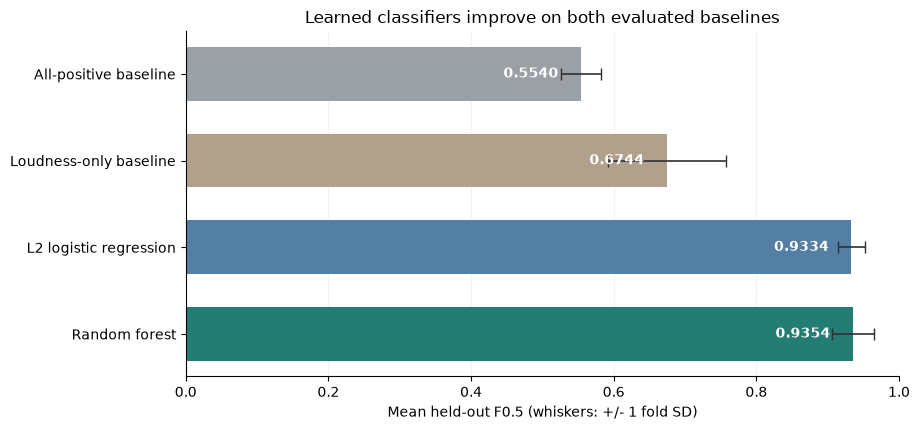

In [117]:
# based on lab 4: mean held-out F0.5 +/- one fold standard deviation
score_tables = {
    "All-positive baseline": all_positive_df,
    "Loudness-only baseline": loudness_df,
    "L2 logistic regression": logistic_df,
    "Random forest": rf_df,
}
summary = pd.DataFrame({name: {"mean": df["f05"].mean(), "sd": df["f05"].std(ddof=1)}
                        for name, df in score_tables.items()}).T
fig, ax = plt.subplots(figsize=(9.3, 4.4))
y_pos = np.arange(len(summary))
colors = ["#9AA0A6", "#B1A18C", "#537FA5", "#247D73"]
bars = ax.barh(y_pos, summary["mean"], xerr=summary["sd"],
               error_kw={"ecolor":"#303030", "capsize":4, "elinewidth":1.2},
               color=colors, height=0.62)
for i, mean in enumerate(summary["mean"]):
    ax.text(mean - 0.07, i, f"{mean:.4f}", ha="center", va="center",
            color="white", fontweight="semibold", fontsize=10)
ax.set(yticks=y_pos, yticklabels=summary.index,
       xlim=(0, 1.0), xlabel="Mean held-out F0.5 (whiskers: +/- 1 fold SD)",
       title="Learned classifiers improve on both evaluated baselines")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.14)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

#### Figure 2
Based on lab 2's focus on how the threshold changes the decision. Each outer fold's threshold was selected using only the inner validation folds. At shift=0, the predictions are equal to the reported held-out decisions. Moving left flags the recordings (reducing false negatives and the cost of more false positives).

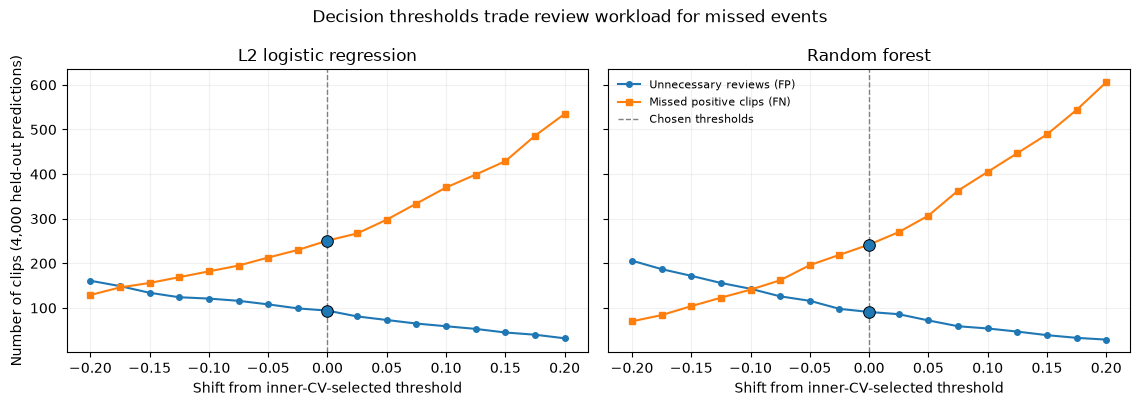

In [112]:
#based on lab 2: counting errors as decision threshold changes
#each recording uses the threshold that was independently selected for its outer fold.
#the shifts are POST-HOC diagnostics only; do not tune on these held-out curves!!!
shifts = np.linspace(-0.20, 0.20, 17)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.1), sharey=True)
for ax, name, oof, fold_scores in [
    (axes[0], "L2 logistic regression", logistic_oof, logistic_df),
    (axes[1], "Random forest", rf_oof, rf_df),
]:
    tbl = oof.merge(fold_scores[["fold", "threshold"]], on="fold", validate="many_to_one")
    y_true = tbl["actual"].to_numpy()
    proba = tbl["probability"].to_numpy()
    chosen = tbl["threshold"].to_numpy()
    fp_values, fn_values = [], []
    for shift in shifts:
        pred = (proba >= np.clip(chosen + shift, 0, 1)).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        fp_values.append(int(fp))
        fn_values.append(int(fn))
    #zero shift = reproduces
    zero = int(np.argmin(np.abs(shifts)))
    assert fp_values[zero] == int(fold_scores["false_positives"].sum())
    assert fn_values[zero] == int(fold_scores["false_negatives"].sum())
    ax.plot(shifts, fp_values, "o-", markersize=4, label="Unnecessary reviews (FP)")
    ax.plot(shifts, fn_values, "s-", markersize=4, label="Missed positive clips (FN)")
    ax.axvline(0, color="grey", ls="--", lw=1, label="Chosen thresholds")
    ax.scatter([0, 0], [fp_values[zero], fn_values[zero]], s=70, zorder=4,
               edgecolors="black", linewidths=0.7)
    ax.set_title(name)
    ax.set_xlabel("Shift from inner-CV-selected threshold")
    ax.grid(alpha=0.18)
axes[0].set_ylabel("Number of clips (4,000 held-out predictions)")
axes[1].legend(fontsize=8, frameon=False)
fig.suptitle("Decision thresholds trade review workload for missed events", fontsize=12)
fig.tight_layout()
plt.show()

### **5. PCA - Dimensionality Reduction**

In [79]:
from sklearn.decomposition import PCA
#test different number of principal components
pca_components = [10, 20, 30, 40]
# Reuse logistic regression hyperparameters, variables C_values and threshold_values

In [81]:
#PCA logistic regression pipeline
def create_pca_logistic_model(n_components, C):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_components)),
        ("model", LogisticRegression(
            l1_ratio=0,
            C=C,
            max_iter=2000,
            random_state=42
        ))
    ])

In [82]:
#nested cv
pca_results = []
pca_predictions = []

inner_cv = LeaveOneGroupOut()

for test_fold in sorted(folds.unique()):

    # OUTER CV: Hold out one original fold
    train_mask = folds != test_fold
    test_mask = folds == test_fold

    X_train = X.loc[train_mask]
    y_train = y.loc[train_mask]
    groups_train = folds.loc[train_mask]

    X_test = X.loc[test_mask]
    y_test = y.loc[test_mask]

    best_score = -1
    best_components = None
    best_C = None
    best_threshold = None

    # INNER CV: Choose PCA components, C, and threshold
    for n_components in pca_components:
        for C in C_values:

            inner_probs = np.zeros(len(X_train))

            for train_idx, val_idx in inner_cv.split(
                X_train, y_train, groups=groups_train
            ):

                model = create_pca_logistic_model(
                    n_components, C
                )

                model.fit(
                    X_train.iloc[train_idx],
                    y_train.iloc[train_idx]
                )

                inner_probs[val_idx] = model.predict_proba(
                    X_train.iloc[val_idx]
                )[:, 1]

            # Find best threshold using inner-fold F0.5
            for threshold in threshold_values:

                inner_pred = (
                    inner_probs >= threshold
                ).astype(int)

                fold_scores = []

                for val_fold in sorted(groups_train.unique()):

                    val_mask = (
                        groups_train.to_numpy() == val_fold
                    )

                    score = fbeta_score(
                        y_train.to_numpy()[val_mask],
                        inner_pred[val_mask],
                        beta=0.5,
                        zero_division=0
                    )

                    fold_scores.append(score)

                mean_score = np.mean(fold_scores)

                if mean_score > best_score:
                    best_score = mean_score
                    best_components = n_components
                    best_C = C
                    best_threshold = threshold

    # FINAL FIT: Use all nine outer training folds
    final_model = create_pca_logistic_model(
        best_components, best_C
    )

    final_model.fit(X_train, y_train)

    # OUTER TEST: Evaluate on the held-out fold
    test_probs = final_model.predict_proba(X_test)[:, 1]

    y_pred = (
        test_probs >= best_threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    pca_results.append({
        "fold": test_fold,
        "n_components": best_components,
        "C": best_C,
        "threshold": best_threshold,
        "f05": fbeta_score(
            y_test, y_pred, beta=0.5, zero_division=0
        ),
        "precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "false_positives": fp,
        "false_negatives": fn,
        "explained_variance": (
            final_model.named_steps["pca"]
            .explained_variance_ratio_.sum()
        )
    })

    # Preserve predictions for later analysis
    pca_predictions.append(pd.DataFrame({
        "row_index": X_test.index,
        "fold": test_fold,
        "actual": y_test.to_numpy(),
        "probability": test_probs,
        "predicted": y_pred
    }))

    print(f"Completed Fold {test_fold}")

# Combine results from all 10 folds
pca_df = pd.DataFrame(pca_results)

pca_oof = pd.concat(
    pca_predictions,
    ignore_index=True
).sort_values("row_index").reset_index(drop=True)

pca_df

Completed Fold 1
Completed Fold 2
Completed Fold 3
Completed Fold 4
Completed Fold 5
Completed Fold 6
Completed Fold 7
Completed Fold 8
Completed Fold 9
Completed Fold 10


,fold,n_components,C,threshold,f05,precision,recall,false_positives,false_negatives,explained_variance
0,1,40,0.01,0.60,0.911654,0.919431,0.881818,17,26,0.981560
1,2,20,0.10,0.70,0.911697,0.975460,0.722727,4,61,0.871668
2,3,40,0.10,0.65,0.944882,0.964824,0.872727,7,28,0.981294
3,4,20,1.00,0.65,0.873552,0.887255,0.822727,23,39,0.869756
4,5,40,0.01,0.60,0.941065,0.951923,0.900000,10,22,0.981385
5,6,40,0.10,0.75,0.918919,0.951049,0.809524,7,32,0.981278
6,7,40,0.10,0.70,0.951493,0.974522,0.869318,4,23,0.980825
7,8,40,0.01,0.65,0.911063,0.903226,0.943820,18,10,0.981030
8,9,40,0.01,0.65,0.973872,0.993939,0.901099,1,18,0.980659
9,10,40,0.10,0.55,0.930493,0.954023,0.846939,8,30,0.981064


In [83]:
print("Mean F0.5:", pca_df["f05"].mean())
print("Mean precision:", pca_df["precision"].mean())
print("Mean recall:", pca_df["recall"].mean())
print("Total false positives:", pca_df["false_positives"].sum())
print("Total false negatives:", pca_df["false_negatives"].sum())

print("\nSelected PCA components:")
print(pca_df["n_components"].value_counts().sort_index())

print("\nMean explained variance:")
print(pca_df["explained_variance"].mean())

Mean F0.5: 0.926868940561015
Mean precision: 0.9475652934746451
Mean recall: 0.8570699892670197
Total false positives: 99
Total false negatives: 289

Selected PCA components:
n_components
20    2
40    8
Name: count, dtype: int64

Mean explained variance:
0.9590518847988749


In [85]:
#compare to logistic regression
without_pca = logistic_oof.set_index("row_index").sort_index()
with_pca = pca_oof.set_index("row_index").sort_index()

assert len(with_pca) == len(data)
assert with_pca.index.is_unique
assert without_pca.index.equals(with_pca.index)
assert (without_pca["actual"] == with_pca["actual"]).all()

decision_changes = (
    without_pca["predicted"] != with_pca["predicted"]
).sum()

print("PCA prediction validation success")
print("Recordings with changed decisions:", decision_changes)

PCA prediction validation success
Recordings with changed decisions: 113


| Metric         | No PCA | With PCA |
|----------------|--------|----------|
| Mean $F_{0.5}$ | 0.9334 | 0.9269   |
| Mean precision | 0.9498 | 0.9476   |
| Mean recall    | 0.8762 | 0.8571   |
| Total FP       | 94     | 99       |
| Total FN       | 251    | 289      |

#### Figure 3
This figure compares logistic regression with and without PCA using the same ten original held-out folds. Each bar represents the difference in $F_{0.5}$ between the PCA and no-PCA models for one fold.

- **Positive values:** PCA improved $F_{0.5}$ for that fold.
- **Negative values:** PCA decreased $F_{0.5}$ for that fold.
- **Dashed horizontal line:** Average difference in $F_{0.5}$ across all ten folds.

PCA was fitted within the cross-validation pipelines to prevent data leakage. The number of principal components was selected through inner cross-validation.

The purpose of this comparison is to determine whether reducing feature dimensionality improves held-out classification performance. The fold numbers represent separate evaluation groups, not a time series.

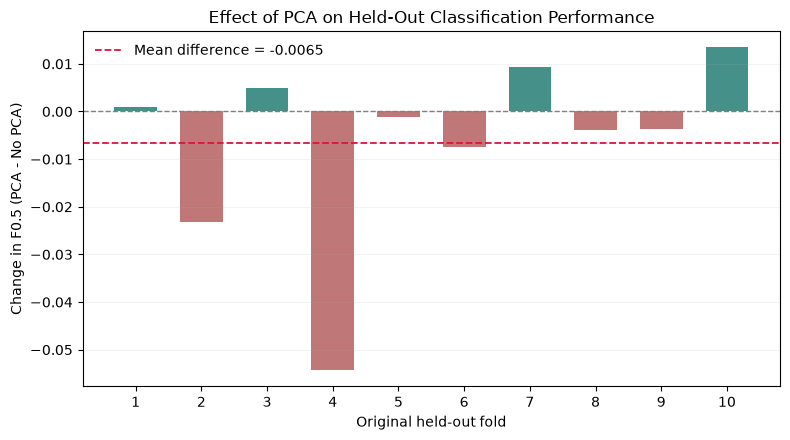

Mean F0.5 without PCA: 0.9334
Mean F0.5 with PCA: 0.9269
Mean F0.5 difference: -0.0065
Selected PCA component counts: {20: 2, 40: 8}
Mean explained variance retained: 95.9%
PCA changed 113 of 4,000 held-out recording decisions.


In [115]:
# Figure 3: PCA versus no-PCA performance across held-out folds

# Compare the same original folds
pca_compare = logistic_df[["fold", "f05"]].merge(
    pca_df[["fold", "f05"]],
    on="fold",
    suffixes=("_no_pca", "_with_pca"),
    validate="one_to_one"
)

# Calculate the F0.5 difference for each fold
pca_compare["delta"] = (
    pca_compare["f05_with_pca"]
    - pca_compare["f05_no_pca"]
)

# Plot differences
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.axhline(0, color="grey", linestyle="--", linewidth=1)

bar_colors = np.where(
    pca_compare["delta"] >= 0,
    "#247D73",
    "#B45F5F"
)

ax.bar(
    pca_compare["fold"],
    pca_compare["delta"],
    width=0.65,
    color=bar_colors,
    alpha=0.85
)

# Show average change across folds
mean_delta = pca_compare["delta"].mean()

ax.axhline(
    mean_delta,
    color="crimson",
    linestyle="--",
    linewidth=1.3,
    label=f"Mean difference = {mean_delta:+.4f}"
)

ax.set(
    xticks=sorted(pca_compare["fold"]),
    xlabel="Original held-out fold",
    ylabel="Change in F0.5 (PCA - No PCA)",
    title="Effect of PCA on Held-Out Classification Performance"
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.15)

fig.tight_layout()
plt.show()

# Summarize actual nested-CV results
print(f"Mean F0.5 without PCA: {logistic_df['f05'].mean():.4f}")
print(f"Mean F0.5 with PCA: {pca_df['f05'].mean():.4f}")
print(f"Mean F0.5 difference: {mean_delta:+.4f}")

print(
    "Selected PCA component counts:",
    pca_df["n_components"].value_counts().sort_index().to_dict()
)

print(
    f"Mean explained variance retained: "
    f"{pca_df['explained_variance'].mean():.1%}"
)

print(
    f"PCA changed {decision_changes:,} "
    f"of {len(data):,} held-out recording decisions."
)

### **6. Failure & Subgroup Analysis**
We can compare two non-target variables, rms_mean (RMS loudness) and duration (length of recording) to investigate if model performance varies across different recording characteristics.
For rms_mean, quieter jackhammer recordings could be more difficult to distinguish from non-distruptive sounds. For duration, shorter recordings could contain less acoustic feature information, making it more difficult for the model to recognize distinctive patterns.

L2-regularized logistic regression and random forest achieved similar $F_{0.5}$ scores with different approaches.


In [88]:
# inspect rms and duration
print("Loudness summary:")
print(data["rms_mean"].describe())

print("\nDuration summary:")
print(data["duration"].describe())

print("\nMissing values:")
print(data[["rms_mean", "duration"]].isna().sum())

Loudness summary:
count    4000.000000
mean        0.064041
std         0.050767
min         0.000387
25%         0.027042
50%         0.054135
75%         0.087138
max         0.579350
Name: rms_mean, dtype: float64

Duration summary:
count    4000.000000
mean        3.779781
std         0.713229
min         0.390000
25%         4.000000
50%         4.000000
75%         4.000000
max         4.036667
Name: duration, dtype: float64

Missing values:
rms_mean    0
duration    0
dtype: int64


In [89]:
#RMS groups
#data copy for subgroup analysis
slice_data = data.copy()

#divide data into lower loudness / higher loudness groups with median
rms_median = slice_data["rms_mean"].median()
slice_data["loudness_group"] = np.where(
    slice_data["rms_mean"] < rms_median,
    "Lower loudness",
    "Higher loudness"
)
print("RMS median:", rms_median)
print("\nLoudness group sizes:")
print(slice_data["loudness_group"].value_counts())

RMS median: 0.054134804999999994

Loudness group sizes:
loudness_group
Lower loudness     2000
Higher loudness    2000
Name: count, dtype: int64


In [90]:
#duration groups
slice_data["duration_group"] = np.where(
    slice_data["duration"] < 3.95, #dataset description says recordings are usually up to 4 seconds long
    "Shorter recordings",
    "Full-length recordings"
)

print("Duration group sizes:")
print(slice_data["duration_group"].value_counts())

Duration group sizes:
duration_group
Full-length recordings    3589
Shorter recordings         411
Name: count, dtype: int64


In [92]:
#connect held-out earlier predictions
logistic_pred = logistic_oof.set_index("row_index").sort_index()
rf_pred = rf_oof.set_index("row_index").sort_index()

# Verify each recording has one prediction
assert logistic_pred.index.equals(slice_data.index)
assert rf_pred.index.equals(slice_data.index)

# Verify target labels match
assert (
    logistic_pred["actual"].to_numpy()
    == slice_data["target"].to_numpy()
).all()

assert (
    rf_pred["actual"].to_numpy()
    == slice_data["target"].to_numpy()
).all()

# Verify original fold assignments
assert (
    logistic_pred["fold"].to_numpy()
    == slice_data["fold"].to_numpy()
).all()

assert (
    rf_pred["fold"].to_numpy()
    == slice_data["fold"].to_numpy()
).all()

# Attach model predictions
slice_data["logistic_pred"] = logistic_pred["predicted"].to_numpy()
slice_data["rf_pred"] = rf_pred["predicted"].to_numpy()

print("Held-out predictions successfully aligned")

Held-out predictions successfully aligned


In [93]:
print("Loudness groups by target:")
print(pd.crosstab(
    slice_data["loudness_group"],
    slice_data["target"]
))

print("\nDuration groups by target:")
print(pd.crosstab(
    slice_data["duration_group"],
    slice_data["target"]
))

Loudness groups by target:
target              0     1
loudness_group             
Higher loudness   646  1354
Lower loudness   1354   646

Duration groups by target:
target                     0     1
duration_group                    
Full-length recordings  1976  1613
Shorter recordings        24   387


The shorter-recording subgroup contains 411 recordings, including 387 positive recordings and only 24 negative recordings. Because this subgroup contains relatively few negative examples, the estimated false-positive rate is uncertain. Both models produced zero false positives in this subgroup, but this does not guarantee zero false positives in deployment.

**Why the class-count table is more useful here than another graph:** Lower loudness has 646 positives / 1,354 negatives, whereas higher loudness has 1,354 positives / 646 negatives. The shorter group has 387 positives and only 24 negatives (411 total). These differences in prevalence can raise precision and $F_{0.5}$ independently of model quality. Read subgroup results with these exact sample sizes and class counts.

**Class balance caveat:** The shorter-duration group contains 411 recordings, of which 387 are positive and only 24 are negative. Precision/$F_{0.5}$ are affected by this class prevalence; observing zero false positives among only 24 negatives does not establish a zero false-positive rate in deployment.

In [94]:
#performance per subgroup
def evaluate_subgroups(df, group_col, pred_col, model_name):
    results = []

    for group_name, subset in df.groupby(group_col):

        actual = subset["target"]
        predicted = subset[pred_col]

        tn, fp, fn, tp = confusion_matrix(
            actual, predicted, labels=[0, 1]
        ).ravel()

        results.append({
            "model": model_name,
            "slice_variable": group_col,
            "subgroup": group_name,
            "n": len(subset),
            "n_positive": int((actual == 1).sum()),
            "n_negative": int((actual == 0).sum()),
            "f05": fbeta_score(
                actual, predicted,
                beta=0.5, zero_division=0
            ),
            "precision": precision_score(
                actual, predicted, zero_division=0
            ),
            "recall": recall_score(
                actual, predicted, zero_division=0
            ),
            "false_positives": fp,
            "false_negatives": fn
        })

    return pd.DataFrame(results)

In [96]:
#apply performance to 2 models x 2 slice variables x 2 subgroups
slice_results = pd.concat([
    evaluate_subgroups(
        slice_data, "loudness_group",
        "logistic_pred", "Logistic regression"
    ),
    evaluate_subgroups(
        slice_data, "loudness_group",
        "rf_pred", "Random forest"
    ),
    evaluate_subgroups(
        slice_data, "duration_group",
        "logistic_pred", "Logistic regression"
    ),
    evaluate_subgroups(
        slice_data, "duration_group",
        "rf_pred", "Random forest"
    )
], ignore_index=True)

print(slice_results.round(4).to_string(index=False))

              model slice_variable               subgroup    n  n_positive  n_negative    f05  precision  recall  false_positives  false_negatives
Logistic regression loudness_group        Higher loudness 2000        1354         646 0.9544     0.9663  0.9099               43              122
Logistic regression loudness_group         Lower loudness 2000         646        1354 0.8859     0.9102  0.8003               51              129
      Random forest loudness_group        Higher loudness 2000        1354         646 0.9575     0.9736  0.8981               33              138
      Random forest loudness_group         Lower loudness 2000         646        1354 0.8897     0.9033  0.8390               58              104
Logistic regression duration_group Full-length recordings 3589        1613        1976 0.9244     0.9376  0.8754               94              201
Logistic regression duration_group     Shorter recordings  411         387          24 0.9712     1.0000  0.8708      

Both models look to perform worse on lower-loudness recordings, as we can see with lower $F_{0.5}$ scores.

In [98]:
#lowest performing subgroup
worst_slices = (
    slice_results
    .loc[slice_results.groupby("model")["f05"].idxmin()]
)
print(worst_slices.to_string(index=False))

              model slice_variable       subgroup    n  n_positive  n_negative      f05  precision   recall  false_positives  false_negatives
Logistic regression loudness_group Lower loudness 2000         646        1354 0.885881   0.910211 0.800310               51              129
      Random forest loudness_group Lower loudness 2000         646        1354 0.889691   0.903333 0.839009               58              104


We can now calculate 95% confidence intervals, resampling entire folds rather than individual recordings to preserve the original dataset's folds.
Bootstrapping this will allow us to estimate how the $F_{0.5}$ score might vary.

| Metric              | Logistic regression | Random forest |
|---------------------|---------------------|---------------|
| Worst subgroup      | Lower loudness      | Lower loudness |
| Subgroup size       | 2,000               | 2,000         |
| Positive recordings | 646                 | 646           |
| Negative recordings | 1,354               | 1,354         |
| $F_{0.5}$           | 0.8859              | 0.8897        |
| Precision           | 0.9102              | 0.9033        |
| Recall              | 0.8003              | 0.8390        |
| False positives     | 51                  | 58            |
| False negatives     | 129                 | 104           |

In [100]:
#95% CI, fold-bootstrap
def bootstrap_f05(df, group_col, group_name, pred_col,
                  n_boot=5000, seed=42):

    subset = df[df[group_col] == group_name]

    # Count true positives, false positives, and false negatives by fold
    counts = []

    for fold in sorted(df["fold"].unique()):
        part = subset[subset["fold"] == fold]

        actual = part["target"]
        predicted = part[pred_col]

        tp = ((actual == 1) & (predicted == 1)).sum()
        fp = ((actual == 0) & (predicted == 1)).sum()
        fn = ((actual == 1) & (predicted == 0)).sum()

        counts.append([tp, fp, fn])

    counts = np.array(counts)
    rng = np.random.default_rng(seed)

    bootstrap_scores = []

    for _ in range(n_boot):

        # Sample 10 original folds with replacement
        sampled_folds = rng.integers(
            0, len(counts), size=len(counts)
        )

        tp, fp, fn = counts[sampled_folds].sum(axis=0)

        # Calculate F0.5 from confusion-matrix counts
        beta_squared = 0.5 ** 2

        denominator = (
            (1 + beta_squared) * tp
            + fp
            + beta_squared * fn
        )

        f05 = (
            (1 + beta_squared) * tp / denominator
            if denominator > 0 else 0.0
        )

        bootstrap_scores.append(f05)

    return np.percentile(bootstrap_scores, [2.5, 97.5])

In [101]:
#intervals for subgroup
slice_results_ci = slice_results.copy()

ci_lower = []
ci_upper = []

for _, row in slice_results_ci.iterrows():

    pred_col = (
        "logistic_pred"
        if row["model"] == "Logistic regression"
        else "rf_pred"
    )

    lower, upper = bootstrap_f05(
        slice_data,
        group_col=row["slice_variable"],
        group_name=row["subgroup"],
        pred_col=pred_col,
        n_boot=5000,
        seed=42
    )

    ci_lower.append(lower)
    ci_upper.append(upper)

slice_results_ci["ci_lower"] = ci_lower
slice_results_ci["ci_upper"] = ci_upper

print(
    slice_results_ci[
        [
            "model",
            "subgroup",
            "n",
            "f05",
            "ci_lower",
            "ci_upper"
        ]
    ].round(4).to_string(index=False)
)

              model               subgroup    n    f05  ci_lower  ci_upper
Logistic regression        Higher loudness 2000 0.9544    0.9393    0.9677
Logistic regression         Lower loudness 2000 0.8859    0.8523    0.9176
      Random forest        Higher loudness 2000 0.9575    0.9379    0.9750
      Random forest         Lower loudness 2000 0.8897    0.8536    0.9210
Logistic regression Full-length recordings 3589 0.9244    0.9074    0.9419
Logistic regression     Shorter recordings  411 0.9712    0.9501    0.9855
      Random forest Full-length recordings 3589 0.9304    0.9045    0.9518
      Random forest     Shorter recordings  411 0.9591    0.9419    0.9773


In [102]:
#extracting the final worst-subgroup
worst_slices_ci = slice_results_ci.loc[
    slice_results_ci.groupby("model")["f05"].idxmin()
]

print(
    worst_slices_ci[
        ["model", "subgroup", "n", "f05", "ci_lower", "ci_upper"]
    ].round(4).to_string(index=False)
)

              model       subgroup    n    f05  ci_lower  ci_upper
Logistic regression Lower loudness 2000 0.8859    0.8523    0.9176
      Random forest Lower loudness 2000 0.8897    0.8536    0.9210


| Metric         | Logistic regression | Random forest      |
|----------------|---------------------|--------------------|
| Worst subgroup | Lower loudness      | Lower loudness     |
| Subgroup size  | 2,000               | 2,000              |
| $F_{0.5}$      | 0.8859              | 0.8897             |
| 95% CI         | [0.8523, 0.9176]    | [0.8536, 0.9210]   |

#### Figure 4

Based on lab 3's bootstrap-interval visualization, dots show pooled held-out subgroup $F_{0.5}$ and whiskers show approximate 95% fold-cluster bootstrap intervals. The sample sizes are included in the axis labels as R5 requires. These groups differ in class prevalence: interpret the figure alongside the positive/negative crosstabs above, not as a causal effect of recording duration or loudness. The observed worst-performing slice was selected after examination and is exploratory.

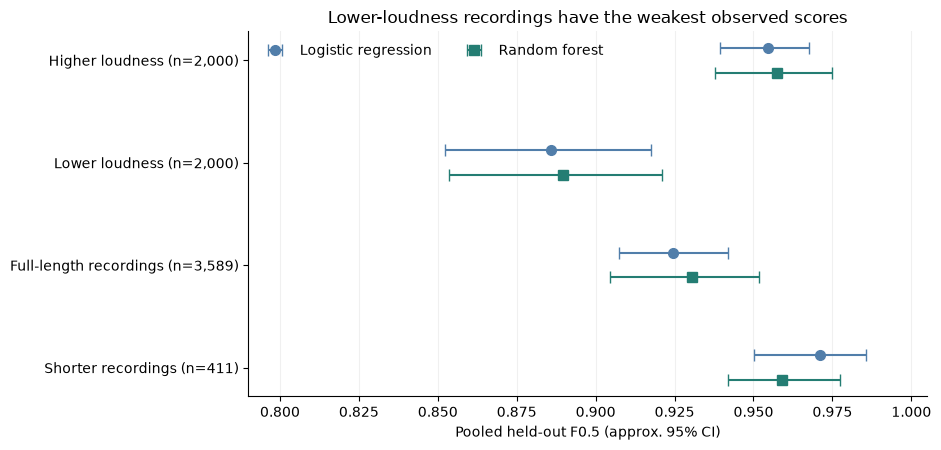

In [116]:
#pooled subgroup F0.5 and fold-bootstrap 95% CI
subgroups = [
    ("loudness_group", "Higher loudness"),
    ("loudness_group", "Lower loudness"),
    ("duration_group", "Full-length recordings"),
    ("duration_group", "Shorter recordings"),
]
fig, ax = plt.subplots(figsize=(9.5, 4.6))
for model, offset, color, marker in [
    ("Logistic regression", -0.12, "#517EAA", "o"),
    ("Random forest", 0.12, "#247D73", "s"),
]:
    rows = slice_results_ci.set_index(["model", "slice_variable", "subgroup"])
    vals = np.array([rows.loc[(model, g, s), "f05"] for g, s in subgroups])
    low = np.array([rows.loc[(model, g, s), "ci_lower"] for g, s in subgroups])
    high = np.array([rows.loc[(model, g, s), "ci_upper"] for g, s in subgroups])
    y_pos = np.arange(len(subgroups)) + offset
    ax.errorbar(vals, y_pos, xerr=[vals-low, high-vals], fmt=marker,
                color=color, capsize=4, markersize=7, lw=1.5, label=model)
counts = slice_results_ci[slice_results_ci["model"] == "Logistic regression"].set_index(
    ["slice_variable", "subgroup"])["n"]
labels = [f"{s} (n={counts.loc[(g,s)]:,})" for g, s in subgroups]
ax.set(yticks=np.arange(len(subgroups)), yticklabels=labels,
       xlim=(0.79, 1.005), xlabel="Pooled held-out F0.5 (approx. 95% CI)",
       title="Lower-loudness recordings have the weakest observed scores")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.18)
ax.legend(frameon=False, loc="upper left", ncol=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### **7. Deployment Recommendation**
This model is intended to be for a municipal noise-monitoring system, flagging audio for human review.

| Metric                  | Logistic regression | Random forest |
|-------------------------|---------------------|---------------|
| Mean $F_{0.5}$          | 0.9334              | **0.9354**    |
| Mean precision          | 0.9498              | **0.9519**    |
| Mean recall             | 0.8762              | **0.8800**    |
| False positives         | 94                  | **91**        |
| False negatives         | 251                 | **242**       |
| Worst-subgroup $F_{0.5}$| 0.8859              | **0.8897**    |

Based on my evaluation, I recommend **L2-regularized logistic regression without PCA** as the initial deployment candidate for municipal noise monitoring. The classifier would identify potential drilling or jackhammer recordings for human review rather than making automatic noise-violation determinations.

**Baseline comparison:** Logistic regression achieved a mean $F_{0.5}$ of 0.9334 across the ten original held-out folds, substantially outperforming the all-positive baseline (0.5540) and loudness-only baseline (0.6744). This suggests the classifier learns useful acoustic information beyond simply predicting every recording as positive or relying on loudness alone.

**Model comparison:** Random forest achieved a slightly higher mean $F_{0.5}$ of 0.9354 compared with logistic regression's 0.9334. Random forest produced 91 false positives and 242 false negatives, compared with 94 and 251 for logistic regression. Although random forest performed slightly better, I favor logistic regression because it has a simpler, more interpretable structure. The small observed performance improvement does not currently justify the additional complexity.

**PCA evaluation:** Adding PCA reduced logistic regression's mean $F_{0.5}$ from 0.9334 to 0.9269 and changed 113 of the 4,000 held-out classification decisions. Since PCA did not improve performance, dimensionality reduction was not selected for deployment.

**Failure analysis:** Lower-loudness recordings were the worst-performing observed subgroup for both models. For logistic regression, this subgroup contained 2,000 recordings and achieved a pooled held-out $F_{0.5}$ of 0.8859 (approximate 95% CI: [0.8523, 0.9176]). This finding is exploratory because the worst subgroup was identified after comparing the evaluated slices. The duration analysis also revealed substantial differences in positive-class prevalence, limiting direct interpretation of subgroup performance. These findings suggest that additional evaluation of quieter recordings is necessary before deployment.

**Decision threshold and error costs:** Classification thresholds were selected using inner cross-validation to prioritize $F_{0.5}$. Our threshold-sensitivity analysis illustrates how flagging more recordings reduces missed positive events but increases unnecessary reviews. We therefore retain the validation-selected operating thresholds rather than choosing new thresholds from held-out test results.

**Condition for reversing the recommendation:** I would recommend random forest instead if an independent evaluation using representative municipal field recordings demonstrated a consistent, practically meaningful reduction in false-positive review workload without an unacceptable increase in missed drilling or jackhammer recordings. Such an evaluation should also examine lower-loudness recordings and variation across recording locations.

Because UrbanSound8K is a curated environmental-audio dataset, these results support further field validation rather than immediate unrestricted deployment.

### Reproducibility check
The following cell prints the exact four model comparisons from freshly recomputed folds. The command in `README.md` reproduces it.

In [ ]:
results_repro = {
    "all_positive": all_positive_df["f05"].mean(),
    "loudness_only": loudness_df["f05"].mean(),
    "logistic_regression": logistic_df["f05"].mean(),
    "random_forest": rf_df["f05"].mean(),
}
print("REPRODUCED HEADLINE (unweighted mean outer-fold F0.5):")
for name, score in results_repro.items():
    print(f"  {name}: {score:.6f}")
assert abs(results_repro["logistic_regression"] - 0.9333893676667445) < 1e-5
assert abs(results_repro["random_forest"] - 0.9354075459525744) < 1e-5


#### Sources
- https://github.com/soundata/soundata#soundata
- Librosa, https://doi.org/10.5281/zenodo.24168548
- https://majormixing.com/what-is-rms-in-audio-world/
- In-class lab notebooks